<center><h1>Zheng_Yifei_HW7</h1></center>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.cluster import KMeans

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [5]:
data = pd.read_csv("anuran+calls+mfccs/Frogs_MFCCs.csv")

feature_columns = [
    column for column in data.columns
    if column.startswith("MFCCs")
]

label_columns = ["Family", "Genus", "Species"]

X = data[feature_columns]
y = data[label_columns]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(
    f"Complete dataset shape: {data.shape}\n"
    f"Training feature shape: {X_train.shape}\n"
    f"Testing feature shape: {X_test.shape}\n"
    f"Training label shape: {y_train.shape}\n"
    f"Testing label shape: {y_test.shape}"
)

Complete dataset shape: (7195, 26)
Training feature shape: (5036, 22)
Testing feature shape: (2159, 22)
Training label shape: (5036, 3)
Testing label shape: (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

Exact match checks whether all labels of one instance are predicted correctly. It is a strict metric because one wrong label makes the whole prediction incorrect.

The exact match score is:

$$
\text{Exact Match}
=
\frac{\text{Number of instances with all labels correct}}
{\text{Total number of instances}}
$$

Hamming loss is the fraction of individual labels that are predicted incorrectly:

$$
\text{Hamming Loss}
=
\frac{\text{Number of incorrect labels}}
{\text{Number of instances} \times \text{Number of labels}}
$$

Hamming score is:

$$
\text{Hamming Score}
=
1-\text{Hamming Loss}
$$

A higher exact match score and Hamming score are better, while a lower Hamming loss is better.

#### (ii) Train a SVM for each of the labels

In [8]:
def multilabel_metrics(y_true, y_pred):
    matches = y_true.to_numpy() == y_pred.to_numpy()
    exact_match = np.mean(np.all(matches, axis=1))
    hamming_score = np.mean(matches)
    hamming_loss_value = 1 - hamming_score

    return exact_match, hamming_score, hamming_loss_value

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rbf_parameters = {
    "estimator__C": np.logspace(-2, 3, 6),
    "estimator__gamma": np.linspace(0.1, 2, 5)
}

rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

for label in label_columns:
    rbf_search = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf")),
        rbf_parameters,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )
    rbf_search.fit(X_train, y_train[label])
    rbf_predictions[label] = rbf_search.predict(X_test)
    rbf_results.append({
        "Label": label,
        "Best C": rbf_search.best_params_["estimator__C"],
        "Best Gamma": rbf_search.best_params_["estimator__gamma"],
        "CV Accuracy": rbf_search.best_score_
    })

rbf_results = pd.DataFrame(rbf_results)
rbf_exact_match, rbf_hamming_score, rbf_hamming_loss = (multilabel_metrics(y_test, rbf_predictions))

rbf_metrics = pd.DataFrame({
    "Exact Match": [rbf_exact_match],
    "Hamming Score": [rbf_hamming_score],
    "Hamming Loss": [rbf_hamming_loss]
})

display(rbf_results)
display(rbf_metrics)

,Label,Best C,Best Gamma,CV Accuracy
0,Family,100.0,1.525,0.992652
1,Genus,10.0,2.000,0.991462
2,Species,100.0,2.000,0.991066


,Exact Match,Hamming Score,Hamming Loss
0,0.988884,0.99228,0.00772


The Gaussian kernel SVM performs well on the test set. The exact match score is 0.9889, which means that about 98.89% of the test instances have all three labels predicted correctly. The Hamming score is 0.9923 and the Hamming loss is 0.0077, so only about 0.77% of the individual labels are predicted incorrectly.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [13]:
c_values = np.logspace(-3, 3, 7)

def run_l1_models(model):
    predictions = pd.DataFrame(index=y_test.index)
    results = []

    for label in label_columns:
        search = GridSearchCV(
            model,
            {"svm__C": c_values},
            scoring="accuracy",
            cv=cv,
            n_jobs=-1
        )

        search.fit(X_train, y_train[label])
        predictions[label] = search.predict(X_test)

        results.append({
            "Label": label,
            "Best C": search.best_params_["svm__C"],
            "CV Accuracy": search.best_score_
        })

    exact_match, hamming_score, loss = multilabel_metrics(y_test, predictions)
    metrics = pd.DataFrame({
        "Exact Match": [exact_match],
        "Hamming Score": [hamming_score],
        "Hamming Loss": [loss]
    })
    return pd.DataFrame(results), predictions, metrics

l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "svm",
        LinearSVC(
            penalty="l1",
            dual=False,
            tol=1e-3,
            max_iter=50000,
            random_state=42
        )
    )
])
l1_results, l1_predictions, l1_metrics = run_l1_models(l1_pipeline)

display(l1_results)
display(l1_metrics)

,Label,Best C,CV Accuracy
0,Family,10.0,0.940826
1,Genus,100.0,0.951749
2,Species,10.0,0.960682


,Exact Match,Hamming Score,Hamming Loss
0,0.912923,0.943029,0.056971


The L1-penalized SVM has an exact match score of 0.9129, a Hamming score of 0.9430, and a Hamming loss of 0.0570.

Its performance is lower than the Gaussian kernel SVM. The Gaussian SVM has a higher exact match score and a lower Hamming loss. This suggests that the nonlinear Gaussian kernel works better for this dataset.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [16]:
smote_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    (
        "svm",
        LinearSVC(
            penalty="l1",
            dual=False,
            tol=1e-3,
            max_iter=50000,
            random_state=42
        )
    )
])
smote_results, smote_predictions, smote_metrics = run_l1_models(smote_pipeline)
model_comparison = pd.concat([
    rbf_metrics.assign(Model="Gaussian SVM"),
    l1_metrics.assign(Model="L1-SVM"),
    smote_metrics.assign(Model="L1-SVM with SMOTE")
], ignore_index=True)[[
    "Model",
    "Exact Match",
    "Hamming Score",
    "Hamming Loss"
]]

display(smote_results)
display(smote_metrics)
display(model_comparison)

,Label,Best C,CV Accuracy
0,Family,100.0,0.922957
1,Genus,10.0,0.913036
2,Species,100.0,0.958501


,Exact Match,Hamming Score,Hamming Loss
0,0.853173,0.922804,0.077196


,Model,Exact Match,Hamming Score,Hamming Loss
0,Gaussian SVM,0.988884,0.992280,0.007720
1,L1-SVM,0.912923,0.943029,0.056971
2,L1-SVM with SMOTE,0.853173,0.922804,0.077196


The L1-SVM with SMOTE has an exact match score of 0.8532, a Hamming score of 0.9228, and a Hamming loss of 0.0772.

SMOTE does not improve the overall performance in this case. The exact match and Hamming scores decrease, while the Hamming loss increases. The Gaussian SVM performs the best among the three models, followed by the L1-SVM without SMOTE.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [19]:
from sklearn.metrics import calinski_harabasz_score

selected_k = []
cluster_assignments = []

for run in range(50):
    best_score = -np.inf
    best_k = None
    best_clusters = None

    for k in range(2, 51):
        clusters = KMeans(n_clusters=k, n_init=1, random_state=run).fit_predict(X)
        score = calinski_harabasz_score(X, clusters)
        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    selected_k.append(best_k)
    cluster_assignments.append(best_clusters)

k_results = pd.Series(selected_k, name="Selected K").value_counts().sort_index().rename_axis("K").reset_index(name="Frequency")
display(k_results)

,K,Frequency
0,2,50


### (b) Determine which family is the majority

In [21]:
majority_labels = []

for clusters in cluster_assignments:
    clustered_labels = y.copy()
    clustered_labels["Cluster"] = clusters

    majority = clustered_labels.groupby("Cluster")[label_columns].agg(lambda values: values.mode().iat[0])
    majority_labels.append(majority)

display(majority_labels[0].reset_index().rename(columns={"Cluster": "Cluster Number"}))

,Cluster Number,Family,Genus,Species
0,0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [23]:
clustering_metrics = []

for clusters, majority in zip(
    cluster_assignments,
    majority_labels
):
    predicted_labels = majority.loc[clusters, label_columns].reset_index(drop=True)
    actual_labels = y[label_columns].reset_index(drop=True)
    incorrect = predicted_labels.ne(actual_labels)
    hamming_distance = incorrect.sum(axis=1).mean()
    loss = incorrect.to_numpy().mean()
    clustering_metrics.append({
        "Hamming Distance": hamming_distance,
        "Hamming Score": 1 - loss,
        "Hamming Loss": loss
    })

clustering_metrics = pd.DataFrame(clustering_metrics)
clustering_summary = clustering_metrics.agg(["mean", "std"]).rename(index={"mean": "Mean", "std": "Standard Deviation"})

display(clustering_summary)

,Hamming Distance,Hamming Score,Hamming Loss
Mean,8.956220e-01,7.014593e-01,2.985407e-01
Standard Deviation,1.121495e-16,3.364484e-16,1.682242e-16


The Calinski-Harabasz method selected two clusters in all 50 Monte Carlo runs. The mean Hamming distance is 0.8956, the mean Hamming score is 0.7015, and the mean Hamming loss is 0.2985. The standard deviations are almost zero, so the clustering results are stable across the 50 runs.

## 3. ISLR 12.6.2

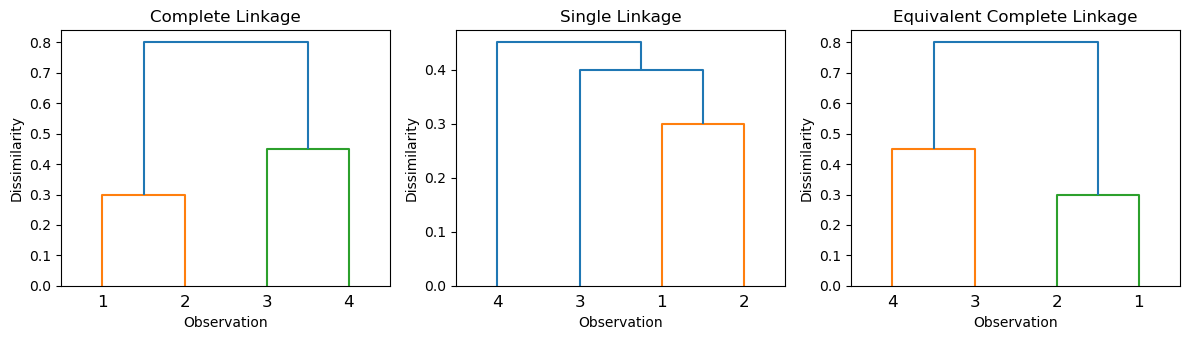

In [26]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

dissimilarity = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

condensed = squareform(dissimilarity)
complete_linkage = linkage(condensed, method="complete")
single_linkage = linkage(condensed, method="single")

equivalent_linkage = complete_linkage.copy()
equivalent_linkage[:, :2] = equivalent_linkage[:, 1::-1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, matrix, title in zip(
    axes,
    [complete_linkage, single_linkage, equivalent_linkage],
    ["Complete Linkage", "Single Linkage", "Equivalent Complete Linkage"]
):
    dendrogram(matrix, labels=["1", "2", "3", "4"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Dissimilarity")

plt.tight_layout()
plt.show()

## (a)

Observations 1 and 2 are first merged at height 0.30. Observations 3 and 4 are merged at height 0.45. Finally, the two clusters are merged at height 0.80.

## (b)

Observations 1 and 2 are first merged at height 0.30. Observation 3 joins this cluster at height 0.40. Observation 4 joins the cluster at height 0.45.

## (c)

When the complete linkage dendrogram is cut to produce two clusters, the clusters are:
- Cluster 1: observations 1 and 2
- Cluster 2: observations 3 and 4

## (d)

When the single linkage dendrogram is cut to produce two clusters, the clusters are:
- Cluster 1: observations 1, 2, and 3
- Cluster 2: observation 4

## (e)

The third dendrogram is equivalent to the complete linkage dendrogram. The leaf positions are changed, but the same observations are merged at the same heights. Therefore, its meaning is unchanged.